## Problem 16: Forecasting the Renewable-Energy Transition Across Countries Using Economic, Emissions and Energy-Mix Indicators

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [4]:
energy_url = (
    "https://raw.githubusercontent.com/"
    "owid/energy-data/master/"
    "owid-energy-data.csv"
)

columns_needed = [
    "country",
    "year",
    "iso_code",
    "population",
    "gdp",

    "renewables_share_elec",
    "fossil_share_elec",
    "coal_share_elec",
    "gas_share_elec",
    "solar_share_elec",
    "wind_share_elec",
    "nuclear_share_elec",

    "carbon_intensity_elec",

    "electricity_demand",
    "per_capita_electricity",

    "energy_per_capita",
    "energy_per_gdp"
]

energy_df = pd.read_csv(
    energy_url,
    usecols=columns_needed
)

energy_df.head()

,country,year,iso_code,population,gdp,carbon_intensity_elec,coal_share_elec,electricity_demand,energy_per_capita,energy_per_gdp,fossil_share_elec,gas_share_elec,nuclear_share_elec,per_capita_electricity,renewables_share_elec,solar_share_elec,wind_share_elec
0,ASEAN (Ember),2000,NaN,NaN,NaN,572.58,20.073,378.76,NaN,NaN,80.666,43.368,0.0,NaN,19.334,0.0,0.0
1,ASEAN (Ember),2001,NaN,NaN,NaN,570.27,21.294,405.09,NaN,NaN,80.945,47.004,0.0,NaN,19.055,0.0,0.0
2,ASEAN (Ember),2002,NaN,NaN,NaN,572.68,21.568,433.19,NaN,NaN,82.333,48.228,0.0,NaN,17.667,0.0,0.0
3,ASEAN (Ember),2003,NaN,NaN,NaN,577.02,22.258,458.30,NaN,NaN,83.332,49.424,0.0,NaN,16.668,0.0,0.0
4,ASEAN (Ember),2004,NaN,NaN,NaN,583.64,23.159,496.61,NaN,NaN,84.304,49.165,0.0,NaN,15.696,0.0,0.0


In [5]:
energy_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23377 entries, 0 to 23376
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   country                 23377 non-null  str    
 1   year                    23377 non-null  int64  
 2   iso_code                17265 non-null  str    
 3   population              18894 non-null  float64
 4   gdp                     11780 non-null  float64
 5   carbon_intensity_elec   6332 non-null   float64
 6   coal_share_elec         7142 non-null   float64
 7   electricity_demand      6378 non-null   float64
 8   energy_per_capita       11086 non-null  float64
 9   energy_per_gdp          7882 non-null   float64
 10  fossil_share_elec       7182 non-null   float64
 11  gas_share_elec          6999 non-null   float64
 12  nuclear_share_elec      7718 non-null   float64
 13  per_capita_electricity  7071 non-null   float64
 14  renewables_share_elec   7872 non-null   float64
 

In [6]:
energy_df.isna().sum()

country                       0
year                          0
iso_code                   6112
population                 4483
gdp                       11597
carbon_intensity_elec     17045
coal_share_elec           16235
electricity_demand        16999
energy_per_capita         12291
energy_per_gdp            15495
fossil_share_elec         16195
gas_share_elec            16378
nuclear_share_elec        15659
per_capita_electricity    16306
renewables_share_elec     15505
solar_share_elec          15508
wind_share_elec           15716
dtype: int64

In [7]:
energy_df.describe().round(2)

,year,population,gdp,carbon_intensity_elec,coal_share_elec,electricity_demand,energy_per_capita,energy_per_gdp,fossil_share_elec,gas_share_elec,nuclear_share_elec,per_capita_electricity,renewables_share_elec,solar_share_elec,wind_share_elec
count,23377.00,1.889400e+04,1.178000e+04,6332.00,7142.00,6378.00,11086.00,7882.00,7182.00,6999.00,7718.00,7071.00,7872.00,7869.00,7661.00
mean,1976.24,1.058587e+08,4.257565e+11,477.17,17.10,647.69,25909.07,1.69,64.95,19.84,5.74,4038.55,29.99,1.12,1.71
std,35.33,4.720948e+08,3.507870e+12,241.45,24.00,2579.03,38288.43,1.64,31.11,26.58,12.98,5042.94,30.60,3.34,4.96
min,1900.00,1.776000e+03,1.642060e+08,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,1949.00,1.599088e+06,1.426394e+10,297.79,0.00,1.54,2833.46,0.77,42.83,0.00,0.00,654.08,3.70,0.00,0.00
50%,1985.00,6.951653e+06,4.357680e+10,523.81,1.71,12.46,12666.64,1.25,70.91,9.96,0.00,2567.54,18.61,0.00,0.00
75%,2005.00,2.581793e+07,1.830576e+11,650.00,31.75,93.57,36635.57,2.07,94.20,27.88,2.19,5745.67,50.00,0.29,0.63
max,2025.00,8.231613e+09,1.301126e+14,1306.72,100.00,31772.35,651836.56,25.25,100.00,100.00,88.01,56048.73,100.00,50.00,58.21


In [8]:
# Remove OWID Regional Aggregates
energy_df = energy_df[
    energy_df["iso_code"].notna()
].copy()

energy_df = energy_df[
    ~energy_df["iso_code"].str.startswith(
        "OWID_"
    )
].copy()

In [9]:
energy_df[[
    "country",
    "iso_code"
]].drop_duplicates().head(20)

,country,iso_code
26,Afghanistan,AFG
523,Albania,ALB
648,Algeria,DZA
773,American Samoa,ASM
818,Angola,AGO
943,Antarctica,ATA
987,Antigua and Barbuda,ATG
1032,Argentina,ARG
1158,Armenia,ARM
1192,Aruba,ABW


In [10]:
energy_df = energy_df[
    energy_df["year"] >= 2000
].copy()

energy_df = energy_df.sort_values(
    by=[
        "country",
        "year"
    ]
)

energy_df.head()

,country,year,iso_code,population,gdp,carbon_intensity_elec,coal_share_elec,electricity_demand,energy_per_capita,energy_per_gdp,fossil_share_elec,gas_share_elec,nuclear_share_elec,per_capita_electricity,renewables_share_elec,solar_share_elec,wind_share_elec
126,Afghanistan,2000,AFG,20130334.0,1.128379e+10,250.00,0.000,0.57,262.680,0.469,35.417,0.0,0.0,23.845,64.583,0.0,0.0
127,Afghanistan,2001,AFG,20284303.0,1.102127e+10,217.39,5.797,0.78,179.892,0.331,27.536,0.0,0.0,34.016,72.464,0.0,0.0
128,Afghanistan,2002,AFG,21378123.0,1.880487e+10,169.01,5.634,0.81,155.695,0.177,21.127,0.0,0.0,33.212,78.873,0.0,0.0
129,Afghanistan,2003,AFG,22733053.0,2.107434e+10,241.76,9.890,1.01,174.558,0.188,30.769,0.0,0.0,40.030,69.231,0.0,0.0
130,Afghanistan,2004,AFG,23560656.0,2.233257e+10,227.85,7.595,0.89,157.758,0.166,29.114,0.0,0.0,33.530,70.886,0.0,0.0


In [11]:
energy_df["gdp_per_capita"] = (
    energy_df["gdp"]
    /
    energy_df["population"]
)

energy_df.loc[
    energy_df["gdp_per_capita"] <= 0,
    "gdp_per_capita"
] = np.nan

In [12]:
energy_df["log_gdp_per_capita"] = np.log(
    energy_df["gdp_per_capita"]
)

In [13]:
energy_df["population_growth"] = (
    energy_df
    .groupby("country")[
        "population"
    ]
    .pct_change(
        fill_method=None
    )
    * 100
)

In [14]:
energy_df["renewable_change"] = (
    energy_df
    .groupby("country")[
        "renewables_share_elec"
    ]
    .diff()
)

In [15]:
# This is our dependent variable
energy_df[
    "future_renewable_change"
] = (
    energy_df
    .groupby("country")[
        "renewables_share_elec"
    ]
    .shift(-1)
    -
    energy_df[
        "renewables_share_elec"
    ]
)

In [16]:
energy_df[
    "electricity_demand_growth"
] = (
    energy_df
    .groupby("country")[
        "electricity_demand"
    ]
    .pct_change(
        fill_method=None
    )
    * 100
)

We only downloaded electricity generation per capita rather than total generation.

To create a broader electricity-growth indicator, calculate annual growth in per-capita electricity generation.

In [17]:
energy_df[
    "electricity_demand_growth"
] = (
    energy_df
    .groupby("country")[
        "electricity_demand"
    ]
    .pct_change(
        fill_method=None
    )
    * 100
)

In [18]:
energy_df = energy_df.rename(
    columns={
        "per_capita_electricity":
        "electricity_per_capita"
    }
)

In [22]:
energy_df["electricity_growth"] = (
    energy_df
    .groupby("country")[
        "electricity_per_capita"
    ]
    .pct_change(
        fill_method=None
    )
    * 100
)

In [23]:
features = [
    "renewables_share_elec",
    "renewable_change",
    "fossil_share_elec",
    "coal_share_elec",
    "gas_share_elec",
    "solar_share_elec",
    "wind_share_elec",
    "nuclear_share_elec",

    "carbon_intensity_elec",

    "electricity_demand_growth",
    "electricity_per_capita",

    "energy_per_capita",
    "energy_per_gdp",

    "log_gdp_per_capita",
    "population_growth",
    "electricity_growth"
]

In [24]:
print(
    "Number of candidate predictors:",
    len(features)
)

Number of candidate predictors: 16


In [26]:
model_df = energy_df[[
    "country",
    "iso_code",
    "year"
] + features + [
    "future_renewable_change"
]].copy()

In [27]:
model_df = model_df.replace(
    [np.inf, -np.inf],
    np.nan
)

In [28]:
model_df = model_df.dropna()

model_df.head()

,country,iso_code,year,renewables_share_elec,renewable_change,fossil_share_elec,coal_share_elec,gas_share_elec,solar_share_elec,wind_share_elec,nuclear_share_elec,carbon_intensity_elec,electricity_demand_growth,electricity_per_capita,energy_per_capita,energy_per_gdp,log_gdp_per_capita,population_growth,electricity_growth,future_renewable_change
127,Afghanistan,AFG,2001,72.464,7.881,27.536,5.797,0.0,0.0,0.0,0.0,217.39,36.842105,34.016,179.892,0.331,6.297735,0.764861,42.654645,6.409
128,Afghanistan,AFG,2002,78.873,6.409,21.127,5.634,0.0,0.0,0.0,0.0,169.01,3.846154,33.212,155.695,0.177,6.779503,5.392446,-2.363594,-9.642
129,Afghanistan,AFG,2003,69.231,-9.642,30.769,9.890,0.0,0.0,0.0,0.0,241.76,24.691358,40.030,174.558,0.188,6.831992,6.337928,20.528725,1.655
130,Afghanistan,AFG,2004,70.886,1.655,29.114,7.595,0.0,0.0,0.0,0.0,227.85,-11.881188,33.530,157.758,0.166,6.854223,3.640527,-16.237822,1.065
131,Afghanistan,AFG,2005,71.951,1.065,28.049,7.317,0.0,0.0,0.0,0.0,219.51,3.370787,33.600,205.468,0.197,6.947643,3.581899,0.208768,-0.840


We do not want a country with only a few observations influencing the model.

In [29]:
country_counts = (
    model_df
    .groupby("country")
    .size()
)

valid_countries = (
    country_counts[
        country_counts >= 12
    ]
    .index
)

model_df = model_df[
    model_df["country"].isin(
        valid_countries
    )
].copy()

In [30]:
print(
    "Countries:",
    model_df["country"].nunique()
)

print(
    "Observations:",
    len(model_df)
)

print(
    "Years:",
    model_df["year"].min(),
    "to",
    model_df["year"].max()
)

Countries: 155
Observations: 3388
Years: 2001 to 2022


In [31]:
model_df[
    features
    + ["future_renewable_change"]
].describe().round(3)

,renewables_share_elec,renewable_change,fossil_share_elec,coal_share_elec,gas_share_elec,solar_share_elec,wind_share_elec,nuclear_share_elec,carbon_intensity_elec,electricity_demand_growth,electricity_per_capita,energy_per_capita,energy_per_gdp,log_gdp_per_capita,population_growth,electricity_growth,future_renewable_change
count,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000,3388.000
mean,34.758,0.287,60.618,13.044,23.797,0.864,1.939,4.624,444.241,3.950,3827.944,25692.564,1.310,9.068,1.488,2.771,0.364
std,33.982,4.738,34.563,22.801,30.307,2.490,5.315,12.768,256.683,9.073,5778.712,35579.409,0.933,1.242,1.597,14.506,4.744
min,0.000,-33.333,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-60.772,4.809,101.881,0.078,6.044,-6.430,-77.159,-32.424
25%,4.858,-0.656,31.360,0.000,0.000,0.000,0.000,0.000,226.775,0.000,393.364,2890.957,0.731,8.086,0.488,-1.895,-0.620
50%,20.936,0.000,67.451,0.000,10.512,0.000,0.000,0.000,485.990,2.931,1908.598,11707.730,1.100,9.214,1.342,1.654,0.000
75%,61.811,1.280,93.302,16.652,39.002,0.364,0.911,0.000,643.318,6.495,4997.379,34361.222,1.632,10.087,2.378,5.501,1.374
max,100.000,52.381,100.000,100.000,100.000,37.879,57.138,80.533,1306.720,133.333,56048.727,270980.625,9.589,12.005,24.234,265.964,52.381


In [32]:
model_df[
    "future_renewable_change"
].describe().round(3)

count    3388.000
mean        0.364
std         4.744
min       -32.424
25%        -0.620
50%         0.000
75%         1.374
max        52.381
Name: future_renewable_change, dtype: float64

**Plot: Distribution of Renewable Transition**

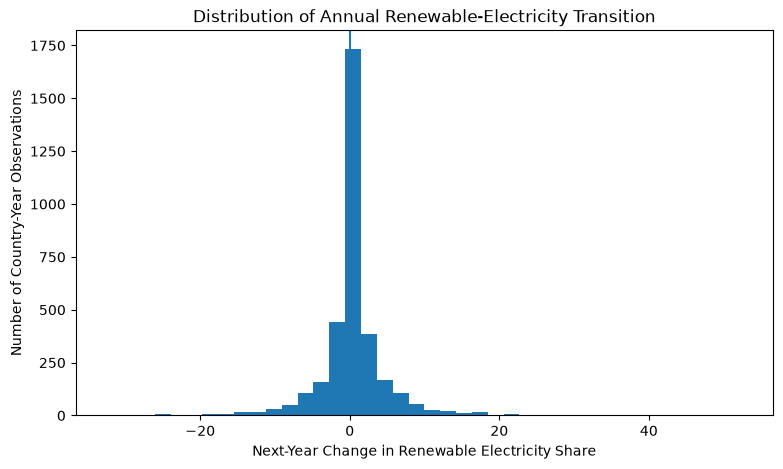

In [33]:
plt.figure(figsize=(9, 5))

plt.hist(
    model_df[
        "future_renewable_change"
    ],
    bins=40
)

plt.axvline(
    x=0
)

plt.xlabel(
    "Next-Year Change in Renewable Electricity Share"
)

plt.ylabel(
    "Number of Country-Year Observations"
)

plt.title(
    "Distribution of Annual Renewable-Electricity Transition"
)

plt.show()

**Average Renewable Transition Through Time**

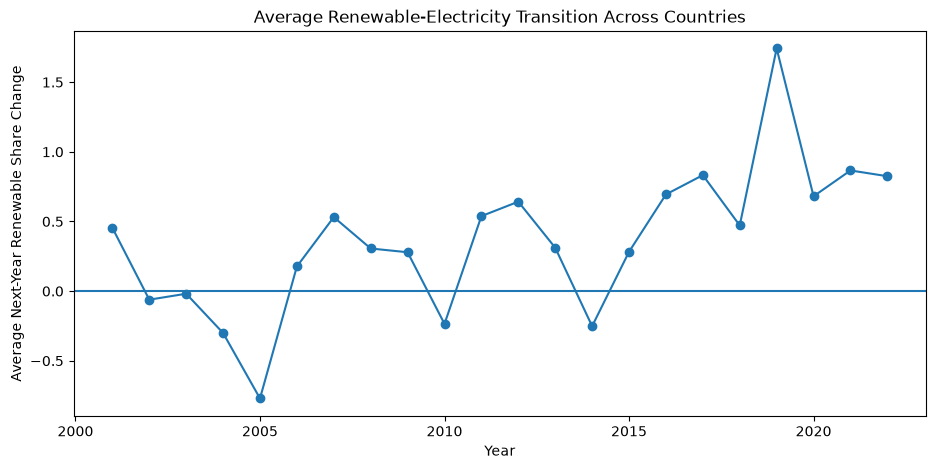

In [34]:
yearly_transition = (
    model_df
    .groupby("year")[
        "future_renewable_change"
    ]
    .mean()
)

plt.figure(figsize=(11, 5))

plt.plot(
    yearly_transition.index,
    yearly_transition.values,
    marker="o"
)

plt.axhline(
    y=0
)

plt.xlabel("Year")

plt.ylabel(
    "Average Next-Year Renewable Share Change"
)

plt.title(
    "Average Renewable-Electricity Transition Across Countries"
)

plt.show()

In [35]:
correlation_matrix = (
    model_df[features]
    .corr()
)

correlation_matrix.round(2)

,renewables_share_elec,renewable_change,fossil_share_elec,coal_share_elec,gas_share_elec,solar_share_elec,wind_share_elec,nuclear_share_elec,carbon_intensity_elec,electricity_demand_growth,electricity_per_capita,energy_per_capita,energy_per_gdp,log_gdp_per_capita,population_growth,electricity_growth
renewables_share_elec,1.00,0.05,-0.93,-0.28,-0.42,0.04,0.11,-0.14,-0.87,0.04,-0.02,-0.21,-0.27,-0.27,0.02,-0.01
renewable_change,0.05,1.00,-0.05,0.01,-0.04,0.14,0.14,0.02,-0.05,0.03,0.02,0.02,0.00,0.05,-0.05,-0.01
fossil_share_elec,-0.93,-0.05,1.00,0.24,0.45,-0.05,-0.12,-0.23,0.93,0.01,-0.07,0.13,0.22,0.15,0.09,0.03
coal_share_elec,-0.28,0.01,0.24,1.00,-0.16,0.01,0.05,0.10,0.40,-0.07,0.06,0.04,0.10,0.22,-0.20,-0.02
gas_share_elec,-0.42,-0.04,0.45,-0.16,1.00,-0.05,-0.05,-0.09,0.40,-0.00,0.12,0.37,0.30,0.35,0.07,0.01
solar_share_elec,0.04,0.14,-0.05,0.01,-0.05,1.00,0.31,0.04,-0.06,-0.10,-0.02,-0.01,-0.10,0.11,-0.06,-0.06
wind_share_elec,0.11,0.14,-0.12,0.05,-0.05,0.31,1.00,0.04,-0.12,-0.11,0.07,0.06,-0.10,0.29,-0.20,-0.05
nuclear_share_elec,-0.14,0.02,-0.23,0.10,-0.09,0.04,0.04,1.00,-0.21,-0.13,0.24,0.20,0.13,0.32,-0.28,-0.06
carbon_intensity_elec,-0.87,-0.05,0.93,0.40,0.40,-0.06,-0.12,-0.21,1.00,0.01,-0.05,0.12,0.30,0.15,0.07,0.02
electricity_demand_growth,0.04,0.03,0.01,-0.07,-0.00,-0.10,-0.11,-0.13,0.01,1.00,-0.10,-0.08,-0.10,-0.18,0.25,0.53


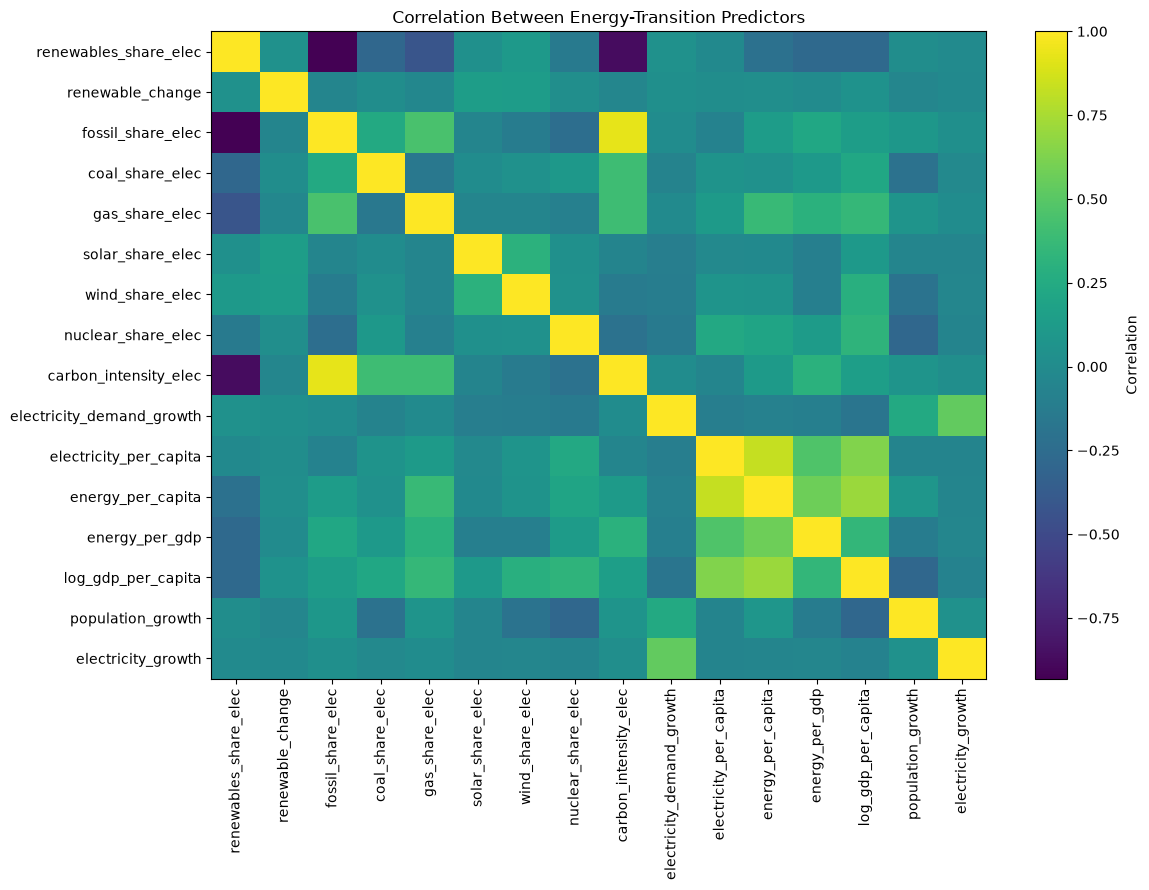

In [36]:
plt.figure(figsize=(12, 9))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(len(features)),
    features,
    rotation=90
)

plt.yticks(
    range(len(features)),
    features
)

plt.title(
    "Correlation Between Energy-Transition Predictors"
)

plt.tight_layout()

plt.show()

In [37]:
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(
            correlation_matrix.shape
        ),
        k=1
    ).astype(bool)
)

correlation_pairs = (
    upper_triangle
    .stack()
    .sort_values(
        key=abs,
        ascending=False
    )
)

correlation_pairs.head(15)

renewables_share_elec      fossil_share_elec       -0.930746
fossil_share_elec          carbon_intensity_elec    0.929204
renewables_share_elec      carbon_intensity_elec   -0.867518
electricity_per_capita     energy_per_capita        0.832668
energy_per_capita          log_gdp_per_capita       0.705942
electricity_per_capita     log_gdp_per_capita       0.630581
energy_per_capita          energy_per_gdp           0.576300
electricity_demand_growth  electricity_growth       0.533453
electricity_per_capita     energy_per_gdp           0.464745
fossil_share_elec          gas_share_elec           0.447467
renewables_share_elec      gas_share_elec          -0.421167
coal_share_elec            carbon_intensity_elec    0.401047
gas_share_elec             carbon_intensity_elec    0.396828
                           energy_per_capita        0.371910
                           log_gdp_per_capita       0.352582
dtype: float64

In [38]:
all_years = np.array(
    sorted(
        model_df["year"].unique()
    )
)

train_years, test_years = train_test_split(
    all_years,
    test_size=0.20,
    shuffle=False
)

In [39]:
train_years = train_years[:-1]

In [40]:
print(
    "Training years:",
    train_years[0],
    "to",
    train_years[-1]
)

print(
    "Test years:",
    test_years[0],
    "to",
    test_years[-1]
)

Training years: 2001 to 2016
Test years: 2018 to 2022


In [41]:
train_df = model_df[
    model_df["year"].isin(
        train_years
    )
].copy()

test_df = model_df[
    model_df["year"].isin(
        test_years
    )
].copy()

In [42]:
train_df = train_df.sort_values(
    by=[
        "year",
        "country"
    ]
).reset_index(drop=True)

test_df = test_df.sort_values(
    by=[
        "year",
        "country"
    ]
).reset_index(drop=True)

In [43]:
X_train = train_df[
    features
]

y_train = train_df[
    "future_renewable_change"
]

X_test = test_df[
    features
]

y_test = test_df[
    "future_renewable_change"
]

In [44]:
print(
    "Training observations:",
    len(X_train)
)

print(
    "Test observations:",
    len(X_test)
)

Training observations: 2460
Test observations: 773


In [45]:
historical_mean = (
    y_train.mean()
)

historical_mean_pred = np.repeat(
    historical_mean,
    len(y_test)
)

print(
    "Historical mean annual renewable-share change:",
    historical_mean
)

Historical mean annual renewable-share change: 0.16124105691056906


In [46]:
scaler = StandardScaler()

X_train_scaled = (
    scaler.fit_transform(
        X_train
    )
)

X_test_scaled = (
    scaler.transform(
        X_test
    )
)

In [47]:
ols = LinearRegression()

ols.fit(
    X_train_scaled,
    y_train
)

ols_pred = ols.predict(
    X_test_scaled
)

ols_coefficients = pd.Series(
    ols.coef_,
    index=features,
    name="OLS"
)

ols_coefficients.round(4)

renewables_share_elec        5759.8453
renewable_change               -0.5587
fossil_share_elec            5846.2703
coal_share_elec                -0.0838
gas_share_elec                 -0.1973
solar_share_elec                0.1999
wind_share_elec                 0.4725
nuclear_share_elec           2194.1412
carbon_intensity_elec          -0.0017
electricity_demand_growth      -0.1964
electricity_per_capita          0.0500
energy_per_capita               0.2015
energy_per_gdp                 -0.1167
log_gdp_per_capita             -0.1419
population_growth              -0.1217
electricity_growth             -0.2416
Name: OLS, dtype: float64

In [48]:
ridge_alpha_values = np.logspace(-4,6,120)

In [49]:
regularisation_alpha_values = np.logspace(-4,2,100)

In [50]:
training_years = np.array(
    sorted(
        train_df["year"].unique()
    )
)

year_splitter = TimeSeriesSplit(
    n_splits=5,
    gap=1
)

cv_splits = []

for year_train_index, year_valid_index in year_splitter.split(
    training_years
):

    cv_train_years = training_years[
        year_train_index
    ]

    cv_valid_years = training_years[
        year_valid_index
    ]

    train_rows = np.where(
        train_df["year"].isin(
            cv_train_years
        )
    )[0]

    valid_rows = np.where(
        train_df["year"].isin(
            cv_valid_years
        )
    )[0]

    cv_splits.append(
        (
            train_rows,
            valid_rows
        )
    )

In [51]:
print(
    "Number of CV folds:",
    len(cv_splits)
)

Number of CV folds: 5


In [52]:
ridge_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "ridge",
        Ridge()
    )
])

ridge_grid = {
    "ridge__alpha":
        ridge_alpha_values
}

In [53]:
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_grid,
    cv=cv_splits,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'ridge__alpha': array([1.0000...00000000e+06])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ..., 754]), ...), (array([ 0, ...shape=(1065,)), ...), ...]"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callabl

In [54]:
best_ridge_alpha = (
    ridge_search
    .best_params_[
        "ridge__alpha"
    ]
)

print(
    "Best Ridge alpha:",
    best_ridge_alpha
)

Best Ridge alpha: 1686.1288382868838


In [55]:
best_ridge = (
    ridge_search
    .best_estimator_
)

ridge_pred = best_ridge.predict(
    X_test
)

In [56]:
ridge_coefficients = pd.Series(
    best_ridge
    .named_steps["ridge"]
    .coef_,
    index=features,
    name="Ridge"
)

ridge_coefficients.round(4)

renewables_share_elec       -0.1648
renewable_change            -0.3173
fossil_share_elec            0.1391
coal_share_elec             -0.0084
gas_share_elec              -0.0718
solar_share_elec             0.1476
wind_share_elec              0.2633
nuclear_share_elec           0.0619
carbon_intensity_elec        0.0805
electricity_demand_growth   -0.1717
electricity_per_capita       0.0315
energy_per_capita            0.0346
energy_per_gdp              -0.0441
log_gdp_per_capita           0.0212
population_growth           -0.0523
electricity_growth          -0.1609
Name: Ridge, dtype: float64

In [57]:
lasso_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "lasso",
        Lasso(
            max_iter=100000
        )
    )
])

lasso_grid = {
    "lasso__alpha":
        regularisation_alpha_values
}

In [58]:
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_grid,
    cv=cv_splits,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'lasso__alpha': array([1.0000...00000000e+02])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ..., 754]), ...), (array([ 0, ...shape=(1065,)), ...), ...]"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable 

In [59]:
best_lasso_alpha = (
    lasso_search
    .best_params_[
        "lasso__alpha"
    ]
)

print(
    "Best LASSO alpha:",
    best_lasso_alpha
)

Best LASSO alpha: 0.14174741629268048


In [60]:
best_lasso = (
    lasso_search
    .best_estimator_
)

lasso_pred = best_lasso.predict(
    X_test
)

In [61]:
lasso_coefficients = pd.Series(
    best_lasso
    .named_steps["lasso"]
    .coef_,
    index=features,
    name="LASSO"
)

lasso_coefficients.round(4)

renewables_share_elec       -0.3145
renewable_change            -0.3961
fossil_share_elec            0.0000
coal_share_elec              0.0000
gas_share_elec              -0.0000
solar_share_elec             0.0963
wind_share_elec              0.3556
nuclear_share_elec           0.0000
carbon_intensity_elec        0.0000
electricity_demand_growth   -0.1652
electricity_per_capita       0.0000
energy_per_capita            0.0000
energy_per_gdp              -0.0000
log_gdp_per_capita           0.0000
population_growth           -0.0000
electricity_growth          -0.1336
Name: LASSO, dtype: float64

In [62]:
l1_ratio_values = [0.05,0.10,0.25,0.50,0.75,0.90,0.95]

In [63]:
elastic_net_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "elastic_net",
        ElasticNet(
            max_iter=100000
        )
    )
])

In [64]:
elastic_net_grid = {
    "elastic_net__alpha":
        regularisation_alpha_values,

    "elastic_net__l1_ratio":
        l1_ratio_values
}

In [65]:
elastic_net_search = GridSearchCV(
    estimator=elastic_net_pipeline,
    param_grid=elastic_net_grid,
    cv=cv_splits,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

elastic_net_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'elastic_net__alpha': array([1.0000...00000000e+02]), 'elastic_net__l1_ratio': [0.05, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ..., 754]), ...), (array([ 0, ...shape=(1065,)), ...), ...]"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated s

In [66]:
best_elastic_alpha = (
    elastic_net_search
    .best_params_[
        "elastic_net__alpha"
    ]
)

best_l1_ratio = (
    elastic_net_search
    .best_params_[
        "elastic_net__l1_ratio"
    ]
)

print(
    "Best Elastic Net alpha:",
    best_elastic_alpha
)

print(
    "Best Elastic Net l1_ratio:",
    best_l1_ratio
)

Best Elastic Net alpha: 0.7564633275546291
Best Elastic Net l1_ratio: 0.05


In [67]:
best_elastic_net = (
    elastic_net_search
    .best_estimator_
)

elastic_net_pred = (
    best_elastic_net.predict(
        X_test
    )
)

In [68]:
elastic_net_coefficients = pd.Series(
    best_elastic_net
    .named_steps["elastic_net"]
    .coef_,
    index=features,
    name="Elastic_Net"
)

elastic_net_coefficients.round(4)

renewables_share_elec       -0.1548
renewable_change            -0.2867
fossil_share_elec            0.1154
coal_share_elec              0.0000
gas_share_elec              -0.0357
solar_share_elec             0.1297
wind_share_elec              0.2448
nuclear_share_elec           0.0442
carbon_intensity_elec        0.0557
electricity_demand_growth   -0.1604
electricity_per_capita       0.0125
energy_per_capita            0.0069
energy_per_gdp              -0.0014
log_gdp_per_capita           0.0175
population_growth           -0.0305
electricity_growth          -0.1419
Name: Elastic_Net, dtype: float64

In [69]:
selected_lasso_features = (
    lasso_coefficients[
        lasso_coefficients != 0
    ]
)

selected_elastic_features = (
    elastic_net_coefficients[
        elastic_net_coefficients != 0
    ]
)

print(
    "Total candidate predictors:",
    len(features)
)

print(
    "LASSO predictors selected:",
    len(
        selected_lasso_features
    )
)

print(
    "Elastic Net predictors selected:",
    len(
        selected_elastic_features
    )
)

Total candidate predictors: 16
LASSO predictors selected: 6
Elastic Net predictors selected: 15


In [70]:
selected_elastic_features

renewables_share_elec       -0.154816
renewable_change            -0.286650
fossil_share_elec            0.115439
gas_share_elec              -0.035728
solar_share_elec             0.129721
wind_share_elec              0.244799
nuclear_share_elec           0.044186
carbon_intensity_elec        0.055684
electricity_demand_growth   -0.160385
electricity_per_capita       0.012475
energy_per_capita            0.006936
energy_per_gdp              -0.001408
log_gdp_per_capita           0.017458
population_growth           -0.030465
electricity_growth          -0.141855
Name: Elastic_Net, dtype: float64

In [71]:
elastic_net_coefficients[
    elastic_net_coefficients == 0
]

coal_share_elec    0.0
Name: Elastic_Net, dtype: float64

In [72]:
selection_table = pd.DataFrame({
    "LASSO":
        lasso_coefficients,

    "Elastic_Net":
        elastic_net_coefficients
})

selection_table[
    "LASSO_Selected"
] = (
    selection_table[
        "LASSO"
    ] != 0
)

selection_table[
    "ElasticNet_Selected"
] = (
    selection_table[
        "Elastic_Net"
    ] != 0
)

selection_table.round(4)

,LASSO,Elastic_Net,LASSO_Selected,ElasticNet_Selected
renewables_share_elec,-0.3145,-0.1548,True,True
renewable_change,-0.3961,-0.2867,True,True
fossil_share_elec,0.0000,0.1154,False,True
coal_share_elec,0.0000,0.0000,False,False
gas_share_elec,-0.0000,-0.0357,False,True
solar_share_elec,0.0963,0.1297,True,True
wind_share_elec,0.3556,0.2448,True,True
nuclear_share_elec,0.0000,0.0442,False,True
carbon_intensity_elec,0.0000,0.0557,False,True
electricity_demand_growth,-0.1652,-0.1604,True,True


In [73]:
coefficient_table = pd.DataFrame({
    "OLS":
        ols_coefficients,

    "Ridge":
        ridge_coefficients,

    "LASSO":
        lasso_coefficients,

    "Elastic_Net":
        elastic_net_coefficients
})

coefficient_table[
    "LASSO_Selected"
] = (
    coefficient_table[
        "LASSO"
    ] != 0
)

coefficient_table[
    "ElasticNet_Selected"
] = (
    coefficient_table[
        "Elastic_Net"
    ] != 0
)

coefficient_table.round(4)

,OLS,Ridge,LASSO,Elastic_Net,LASSO_Selected,ElasticNet_Selected
renewables_share_elec,5759.8453,-0.1648,-0.3145,-0.1548,True,True
renewable_change,-0.5587,-0.3173,-0.3961,-0.2867,True,True
fossil_share_elec,5846.2703,0.1391,0.0000,0.1154,False,True
coal_share_elec,-0.0838,-0.0084,0.0000,0.0000,False,False
gas_share_elec,-0.1973,-0.0718,-0.0000,-0.0357,False,True
solar_share_elec,0.1999,0.1476,0.0963,0.1297,True,True
wind_share_elec,0.4725,0.2633,0.3556,0.2448,True,True
nuclear_share_elec,2194.1412,0.0619,0.0000,0.0442,False,True
carbon_intensity_elec,-0.0017,0.0805,0.0000,0.0557,False,True
electricity_demand_growth,-0.1964,-0.1717,-0.1652,-0.1604,True,True


In [74]:
def evaluate_model(
    y_true,
    y_pred
):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return rmse, mae, r2

In [75]:
mean_rmse, mean_mae, mean_r2 = evaluate_model(
    y_test,
    historical_mean_pred
)

ols_rmse, ols_mae, ols_r2 = evaluate_model(
    y_test,
    ols_pred
)

ridge_rmse, ridge_mae, ridge_r2 = evaluate_model(
    y_test,
    ridge_pred
)

lasso_rmse, lasso_mae, lasso_r2 = evaluate_model(
    y_test,
    lasso_pred
)

elastic_rmse, elastic_mae, elastic_r2 = evaluate_model(
    y_test,
    elastic_net_pred
)

In [76]:
performance = pd.DataFrame({
    "Model": [
        "Historical Mean",
        "OLS",
        "Ridge",
        "LASSO",
        "Elastic Net"
    ],

    "RMSE": [
        mean_rmse,
        ols_rmse,
        ridge_rmse,
        lasso_rmse,
        elastic_rmse
    ],

    "MAE": [
        mean_mae,
        ols_mae,
        ridge_mae,
        lasso_mae,
        elastic_mae
    ],

    "R2": [
        mean_r2,
        ols_r2,
        ridge_r2,
        lasso_r2,
        elastic_r2
    ]
})

performance.round(4)

,Model,RMSE,MAE,R2
0,Historical Mean,4.7964,2.6999,-0.0255
1,OLS,4.7517,2.7388,-0.0065
2,Ridge,4.6890,2.6481,0.0199
3,LASSO,4.6826,2.6329,0.0226
4,Elastic Net,4.6843,2.6344,0.0219


In [77]:
def out_of_sample_r2(
    y_true,
    model_pred,
    benchmark_pred
):

    model_error = np.sum(
        (
            y_true.values
            - model_pred
        ) ** 2
    )

    benchmark_error = np.sum(
        (
            y_true.values
            - benchmark_pred
        ) ** 2
    )

    return (
        1
        -
        model_error
        / benchmark_error
    )

In [78]:
ols_oos_r2 = out_of_sample_r2(
    y_test,
    ols_pred,
    historical_mean_pred
)

ridge_oos_r2 = out_of_sample_r2(
    y_test,
    ridge_pred,
    historical_mean_pred
)

lasso_oos_r2 = out_of_sample_r2(
    y_test,
    lasso_pred,
    historical_mean_pred
)

elastic_oos_r2 = out_of_sample_r2(
    y_test,
    elastic_net_pred,
    historical_mean_pred
)

print(
    "OLS OOS R2:",
    round(
        ols_oos_r2,
        4
    )
)

print(
    "Ridge OOS R2:",
    round(
        ridge_oos_r2,
        4
    )
)

print(
    "LASSO OOS R2:",
    round(
        lasso_oos_r2,
        4
    )
)

print(
    "Elastic Net OOS R2:",
    round(
        elastic_oos_r2,
        4
    )
)

OLS OOS R2: 0.0186
Ridge OOS R2: 0.0443
LASSO OOS R2: 0.0469
Elastic Net OOS R2: 0.0462


In [79]:
elastic_vs_lasso_gain = (
    lasso_rmse
    - elastic_rmse
)

elastic_vs_lasso_percent = (
    elastic_vs_lasso_gain
    / lasso_rmse
    * 100
)

print(
    "Elastic Net RMSE improvement over LASSO:",
    round(
        elastic_vs_lasso_gain,
        4
    )
)

print(
    "Percentage RMSE improvement:",
    round(
        elastic_vs_lasso_percent,
        2
    ),
    "%"
)

Elastic Net RMSE improvement over LASSO: -0.0017
Percentage RMSE improvement: -0.04 %


In [80]:
def direction_accuracy(
    y_true,
    y_pred
):

    correct = (
        np.sign(
            y_true.values
        )
        ==
        np.sign(
            y_pred
        )
    )

    return (
        correct.mean()
        * 100
    )

In [81]:
mean_direction = direction_accuracy(
    y_test,
    historical_mean_pred
)

ols_direction = direction_accuracy(
    y_test,
    ols_pred
)

ridge_direction = direction_accuracy(
    y_test,
    ridge_pred
)

lasso_direction = direction_accuracy(
    y_test,
    lasso_pred
)

elastic_direction = direction_accuracy(
    y_test,
    elastic_net_pred
)

print(
    "Historical Mean Direction Accuracy:",
    round(mean_direction, 2),
    "%"
)

print(
    "OLS Direction Accuracy:",
    round(ols_direction, 2),
    "%"
)

print(
    "Ridge Direction Accuracy:",
    round(ridge_direction, 2),
    "%"
)

print(
    "LASSO Direction Accuracy:",
    round(lasso_direction, 2),
    "%"
)

print(
    "Elastic Net Direction Accuracy:",
    round(elastic_direction, 2),
    "%"
)

Historical Mean Direction Accuracy: 56.02 %
OLS Direction Accuracy: 56.27 %
Ridge Direction Accuracy: 56.27 %
LASSO Direction Accuracy: 56.4 %
Elastic Net Direction Accuracy: 56.27 %


In [82]:
def positive_transition_recall(
    y_true,
    y_pred
):

    actual_positive = (
        y_true.values > 0
    )

    predicted_positive = (
        y_pred > 0
    )

    correctly_predicted = (
        actual_positive
        &
        predicted_positive
    )

    return (
        correctly_predicted.sum()
        /
        actual_positive.sum()
        * 100
    )

In [83]:
ols_positive_recall = positive_transition_recall(
    y_test,
    ols_pred
)

ridge_positive_recall = positive_transition_recall(
    y_test,
    ridge_pred
)

lasso_positive_recall = positive_transition_recall(
    y_test,
    lasso_pred
)

elastic_positive_recall = positive_transition_recall(
    y_test,
    elastic_net_pred
)

print(
    "OLS Positive-Transition Recall:",
    round(
        ols_positive_recall,
        2
    ),
    "%"
)

print(
    "Ridge Positive-Transition Recall:",
    round(
        ridge_positive_recall,
        2
    ),
    "%"
)

print(
    "LASSO Positive-Transition Recall:",
    round(
        lasso_positive_recall,
        2
    ),
    "%"
)

print(
    "Elastic Net Positive-Transition Recall:",
    round(
        elastic_positive_recall,
        2
    ),
    "%"
)

OLS Positive-Transition Recall: 83.14 %
Ridge Positive-Transition Recall: 85.68 %
LASSO Positive-Transition Recall: 86.37 %
Elastic Net Positive-Transition Recall: 86.84 %


In [84]:
test_results = test_df[[
    "country",
    "year",
    "renewables_share_elec",
    "fossil_share_elec"
]].copy()

test_results[
    "Actual"
] = y_test.values

test_results[
    "Historical_Mean"
] = historical_mean_pred

test_results[
    "OLS"
] = ols_pred

test_results[
    "Ridge"
] = ridge_pred

test_results[
    "LASSO"
] = lasso_pred

test_results[
    "Elastic_Net"
] = elastic_net_pred

In [85]:
test_results.head(10).round(3)

,country,year,renewables_share_elec,fossil_share_elec,Actual,Historical_Mean,OLS,Ridge,LASSO,Elastic_Net
0,Afghanistan,2018,82.906,17.094,4.765,0.161,0.684,0.439,0.363,0.416
1,Albania,2018,100.000,0.000,0.000,0.161,-2.252,-1.439,-1.308,-1.277
2,Algeria,2018,1.068,98.932,-0.002,0.161,0.269,0.435,0.502,0.467
3,Angola,2018,79.452,20.548,-6.254,0.161,-2.243,-1.433,-1.458,-1.271
4,Argentina,2018,23.995,71.324,0.932,0.161,-0.127,0.197,0.253,0.222
5,Armenia,2018,30.435,44.532,1.741,0.161,0.129,0.211,0.202,0.210
6,Australia,2018,18.844,81.156,1.938,0.161,1.764,1.453,1.091,1.269
7,Austria,2018,77.408,22.592,-0.113,0.161,1.213,0.856,0.858,0.766
8,Azerbaijan,2018,7.760,92.240,-0.862,0.161,0.077,0.280,0.336,0.306
9,Bahrain,2018,0.034,99.966,0.026,0.161,0.563,0.519,0.416,0.487


In [86]:
yearly_results = (
    test_results
    .groupby("year")[[
        "Actual",
        "Historical_Mean",
        "OLS",
        "Ridge",
        "LASSO",
        "Elastic_Net"
    ]]
    .mean()
)

yearly_results.round(3)

,Actual,Historical_Mean,OLS,Ridge,LASSO,Elastic_Net
year,,,,,,
2018,0.471,0.161,0.738,0.558,0.509,0.512
2019,1.742,0.161,0.953,0.705,0.650,0.645
2020,0.681,0.161,1.051,0.796,0.699,0.729
2021,0.866,0.161,1.130,0.822,0.720,0.747
2022,0.825,0.161,1.517,1.114,0.951,1.008


**Plot: Actual and Forecast Renewable Transition**

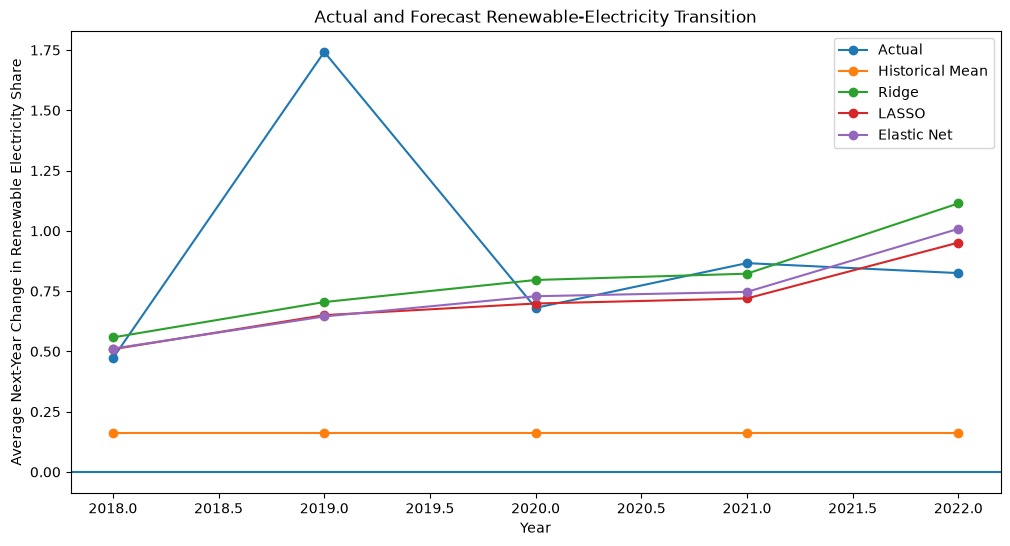

In [87]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_results.index,
    yearly_results["Actual"],
    marker="o",
    label="Actual"
)

plt.plot(
    yearly_results.index,
    yearly_results[
        "Historical_Mean"
    ],
    marker="o",
    label="Historical Mean"
)

plt.plot(
    yearly_results.index,
    yearly_results["Ridge"],
    marker="o",
    label="Ridge"
)

plt.plot(
    yearly_results.index,
    yearly_results["LASSO"],
    marker="o",
    label="LASSO"
)

plt.plot(
    yearly_results.index,
    yearly_results[
        "Elastic_Net"
    ],
    marker="o",
    label="Elastic Net"
)

plt.axhline(
    y=0
)

plt.xlabel("Year")

plt.ylabel(
    "Average Next-Year Change in Renewable Electricity Share"
)

plt.title(
    "Actual and Forecast Renewable-Electricity Transition"
)

plt.legend()

plt.show()

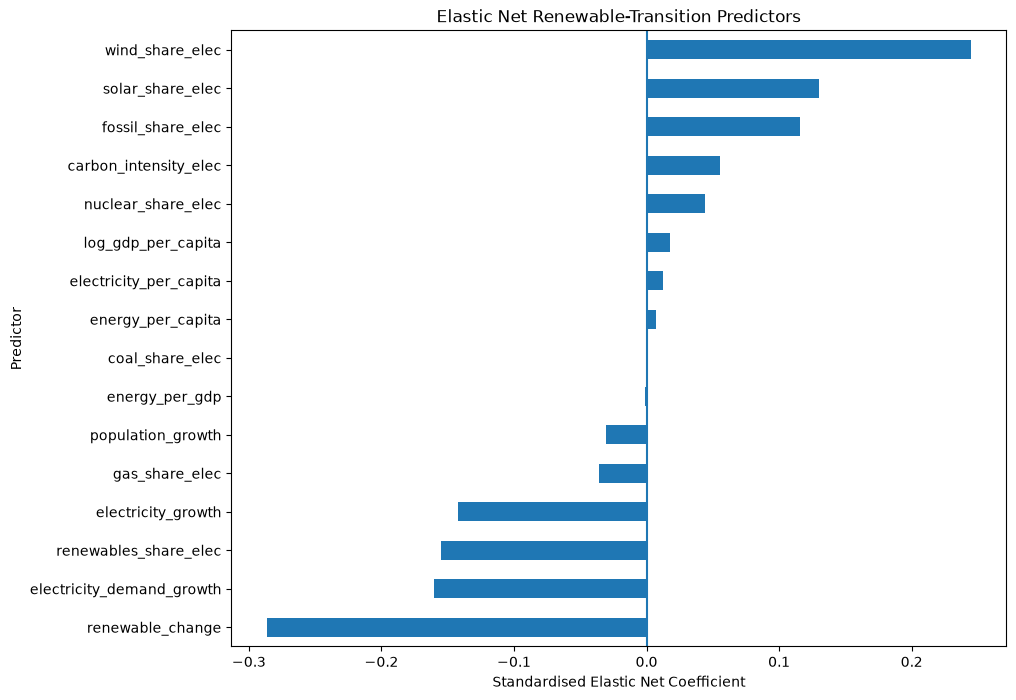

In [88]:
elastic_net_coefficients.sort_values().plot(
    kind="barh",
    figsize=(10, 8)
)

plt.axvline(
    x=0
)

plt.xlabel(
    "Standardised Elastic Net Coefficient"
)

plt.ylabel(
    "Predictor"
)

plt.title(
    "Elastic Net Renewable-Transition Predictors"
)

plt.show()

In [89]:
lasso_elastic_comparison = pd.DataFrame({
    "LASSO":
        lasso_coefficients,

    "Elastic_Net":
        elastic_net_coefficients
})

lasso_elastic_comparison.round(4)

,LASSO,Elastic_Net
renewables_share_elec,-0.3145,-0.1548
renewable_change,-0.3961,-0.2867
fossil_share_elec,0.0000,0.1154
coal_share_elec,0.0000,0.0000
gas_share_elec,-0.0000,-0.0357
solar_share_elec,0.0963,0.1297
wind_share_elec,0.3556,0.2448
nuclear_share_elec,0.0000,0.0442
carbon_intensity_elec,0.0000,0.0557
electricity_demand_growth,-0.1652,-0.1604


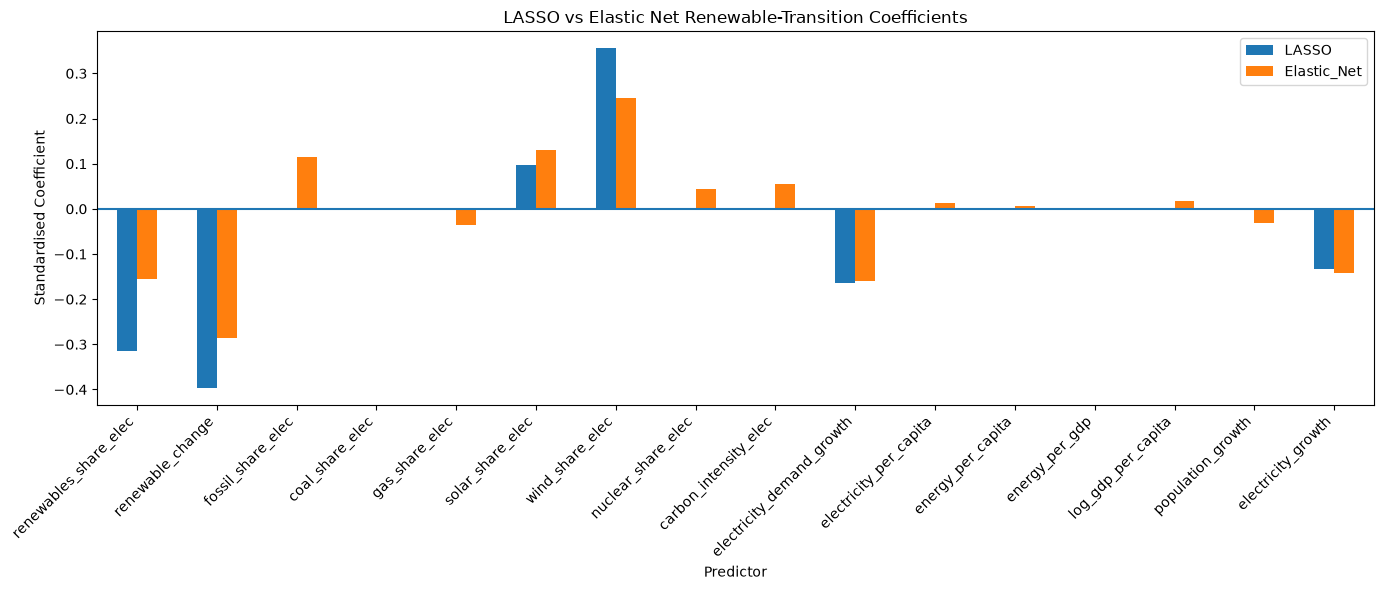

In [90]:
lasso_elastic_comparison.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.axhline(
    y=0
)

plt.xlabel(
    "Predictor"
)

plt.ylabel(
    "Standardised Coefficient"
)

plt.title(
    "LASSO vs Elastic Net Renewable-Transition Coefficients"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

In [91]:
path_scaler = StandardScaler()

X_train_path = (
    path_scaler.fit_transform(
        X_train
    )
)

path_alphas = np.logspace(
    -4,
    2,
    100
)

elastic_coefficient_path = []

for alpha in path_alphas:

    model = ElasticNet(
        alpha=alpha,
        l1_ratio=best_l1_ratio,
        max_iter=100000
    )

    model.fit(
        X_train_path,
        y_train
    )

    elastic_coefficient_path.append(
        model.coef_
    )

elastic_coefficient_path = np.array(
    elastic_coefficient_path
)

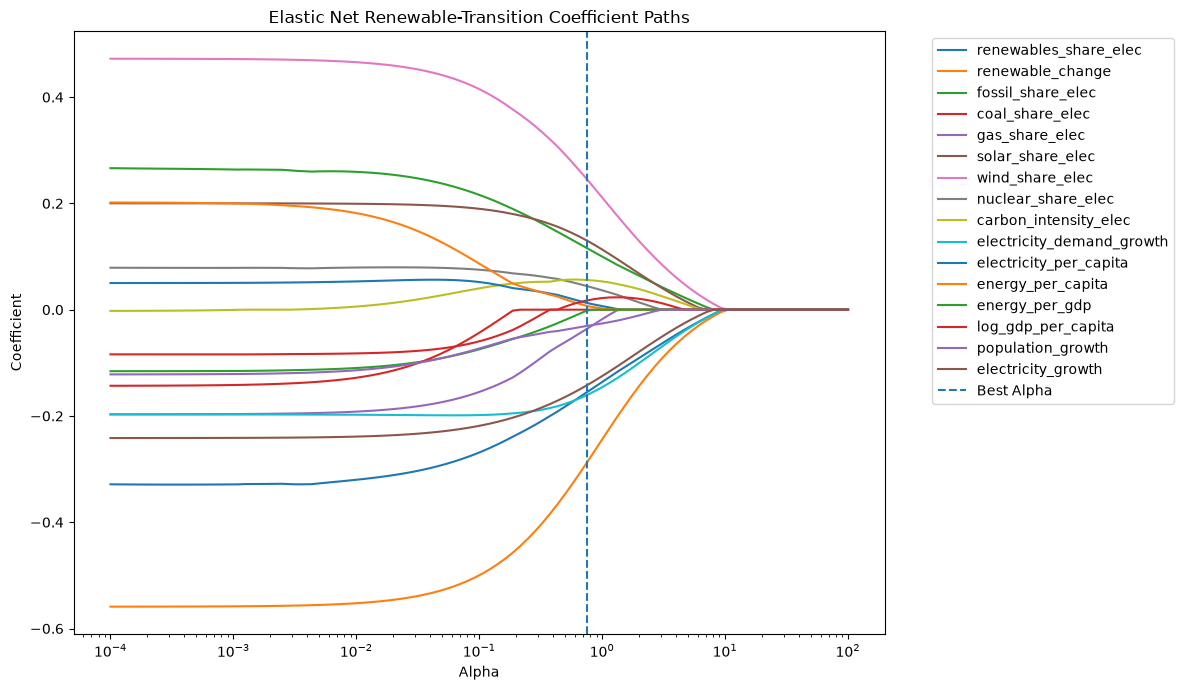

In [92]:
plt.figure(figsize=(12, 7))

for i, feature in enumerate(features):

    plt.semilogx(
        path_alphas,
        elastic_coefficient_path[:, i],
        label=feature
    )

plt.axvline(
    best_elastic_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel("Alpha")

plt.ylabel("Coefficient")

plt.title(
    "Elastic Net Renewable-Transition Coefficient Paths"
)

plt.legend(
    bbox_to_anchor=(
        1.05,
        1
    ),
    loc="upper left"
)

plt.tight_layout()

plt.show()

In [93]:
elastic_cv_results = pd.DataFrame(
    elastic_net_search.cv_results_
)

elastic_cv_results[
    "RMSE"
] = (
    -elastic_cv_results[
        "mean_test_score"
    ]
)

elastic_cv_results[
    "alpha"
] = (
    elastic_cv_results[
        "param_elastic_net__alpha"
    ].astype(float)
)

elastic_cv_results[
    "l1_ratio"
] = (
    elastic_cv_results[
        "param_elastic_net__l1_ratio"
    ].astype(float)
)

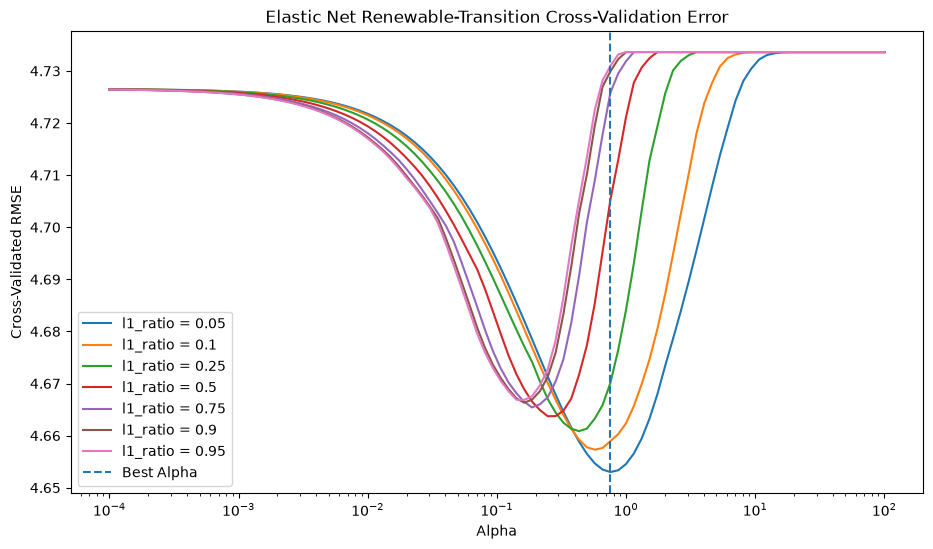

In [94]:
plt.figure(figsize=(11, 6))

for ratio in l1_ratio_values:

    ratio_results = (
        elastic_cv_results[
            elastic_cv_results[
                "l1_ratio"
            ] == ratio
        ]
        .sort_values(
            "alpha"
        )
    )

    plt.semilogx(
        ratio_results["alpha"],
        ratio_results["RMSE"],
        label=f"l1_ratio = {ratio}"
    )

plt.axvline(
    best_elastic_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel("Alpha")

plt.ylabel(
    "Cross-Validated RMSE"
)

plt.title(
    "Elastic Net Renewable-Transition Cross-Validation Error"
)

plt.legend()

plt.show()

In [95]:
lower_fossil_mask = (
    test_results[
        "fossil_share_elec"
    ] <= 70
)

high_fossil_mask = (
    test_results[
        "fossil_share_elec"
    ] > 70
)

In [96]:
lower_fossil_rmse = np.sqrt(
    mean_squared_error(
        test_results.loc[
            lower_fossil_mask,
            "Actual"
        ],
        test_results.loc[
            lower_fossil_mask,
            "Elastic_Net"
        ]
    )
)

high_fossil_rmse = np.sqrt(
    mean_squared_error(
        test_results.loc[
            high_fossil_mask,
            "Actual"
        ],
        test_results.loc[
            high_fossil_mask,
            "Elastic_Net"
        ]
    )
)

print(
    "Elastic Net RMSE for fossil share <= 70%:",
    round(
        lower_fossil_rmse,
        4
    )
)

print(
    "Elastic Net RMSE for fossil share > 70%:",
    round(
        high_fossil_rmse,
        4
    )
)

Elastic Net RMSE for fossil share <= 70%: 5.3757
Elastic Net RMSE for fossil share > 70%: 3.6108


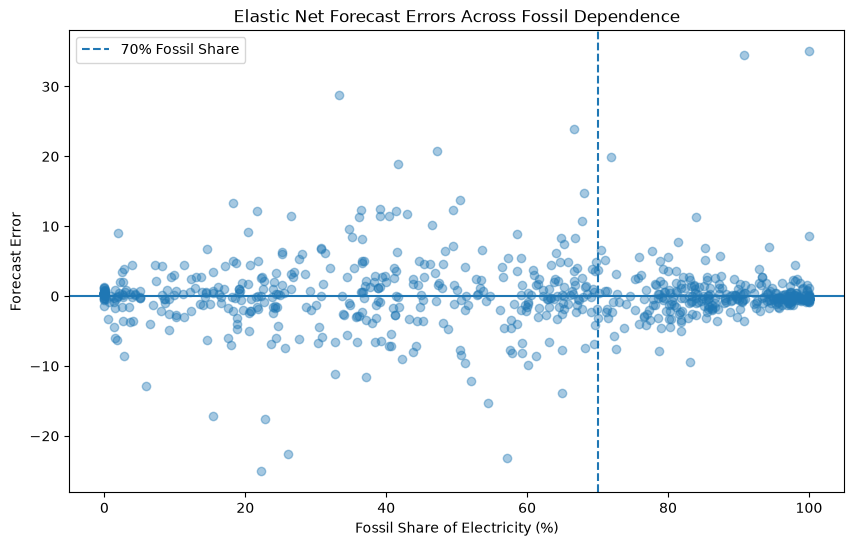

In [97]:
elastic_residuals = (
    y_test.values
    -
    elastic_net_pred
)

plt.figure(figsize=(10, 6))

plt.scatter(
    test_results[
        "fossil_share_elec"
    ],
    elastic_residuals,
    alpha=0.4
)

plt.axhline(
    y=0
)

plt.axvline(
    x=70,
    linestyle="--",
    label="70% Fossil Share"
)

plt.xlabel(
    "Fossil Share of Electricity (%)"
)

plt.ylabel(
    "Forecast Error"
)

plt.title(
    "Elastic Net Forecast Errors Across Fossil Dependence"
)

plt.legend()

plt.show()

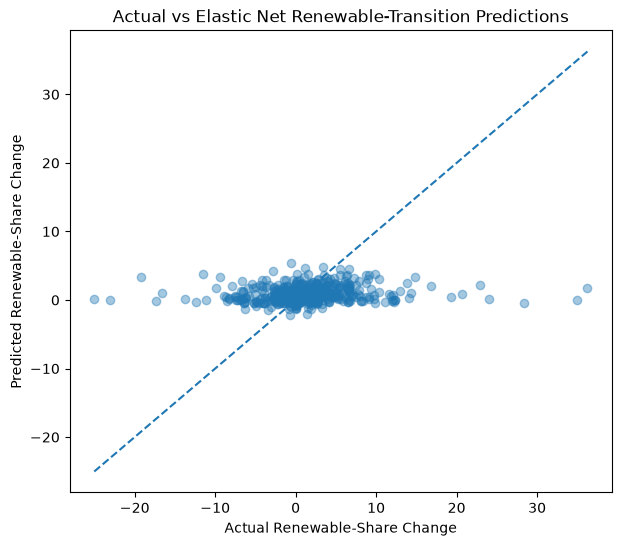

In [98]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    elastic_net_pred,
    alpha=0.4
)

minimum = min(
    y_test.min(),
    elastic_net_pred.min()
)

maximum = max(
    y_test.max(),
    elastic_net_pred.max()
)

plt.plot(
    [
        minimum,
        maximum
    ],
    [
        minimum,
        maximum
    ],
    linestyle="--"
)

plt.xlabel(
    "Actual Renewable-Share Change"
)

plt.ylabel(
    "Predicted Renewable-Share Change"
)

plt.title(
    "Actual vs Elastic Net Renewable-Transition Predictions"
)

plt.show()

In [99]:
benchmark_squared_error = (
    y_test.values
    -
    historical_mean_pred
) ** 2

ridge_squared_error = (
    y_test.values
    -
    ridge_pred
) ** 2

lasso_squared_error = (
    y_test.values
    -
    lasso_pred
) ** 2

elastic_squared_error = (
    y_test.values
    -
    elastic_net_pred
) ** 2

ridge_cumulative_gain = np.cumsum(
    benchmark_squared_error
    -
    ridge_squared_error
)

lasso_cumulative_gain = np.cumsum(
    benchmark_squared_error
    -
    lasso_squared_error
)

elastic_cumulative_gain = np.cumsum(
    benchmark_squared_error
    -
    elastic_squared_error
)

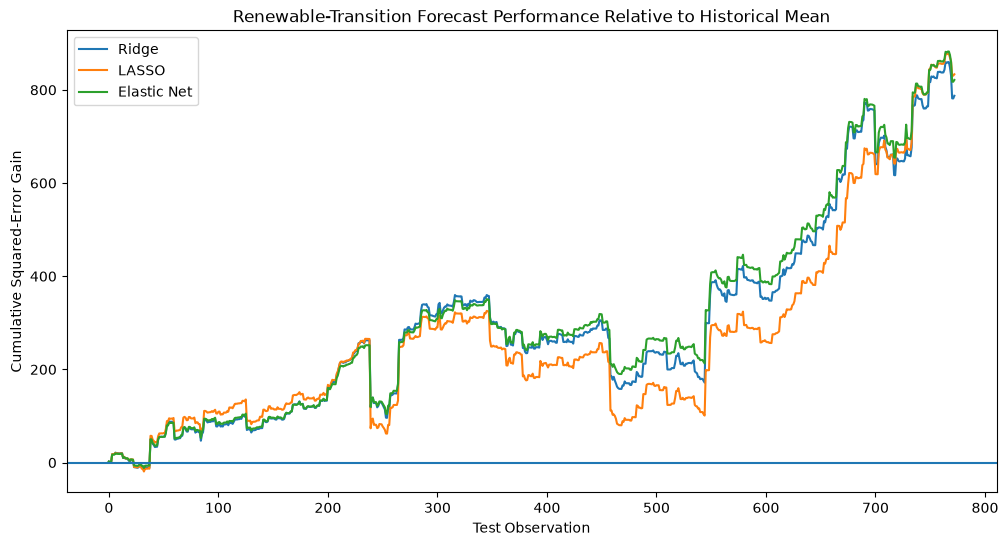

In [100]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_results.index,
    ridge_cumulative_gain,
    label="Ridge"
)

plt.plot(
    test_results.index,
    lasso_cumulative_gain,
    label="LASSO"
)

plt.plot(
    test_results.index,
    elastic_cumulative_gain,
    label="Elastic Net"
)

plt.axhline(
    y=0
)

plt.xlabel(
    "Test Observation"
)

plt.ylabel(
    "Cumulative Squared-Error Gain"
)

plt.title(
    "Renewable-Transition Forecast Performance Relative to Historical Mean"
)

plt.legend()

plt.show()

In [101]:
performance.to_csv(
    "problem_16_model_performance.csv",
    index=False
)

coefficient_table.to_csv(
    "problem_16_coefficients.csv"
)

test_results.to_csv(
    "problem_16_country_year_forecasts.csv",
    index=False
)

yearly_results.to_csv(
    "problem_16_yearly_forecasts.csv"
)

elastic_cv_results.to_csv(
    "problem_16_elastic_net_cv.csv",
    index=False
)

## END